In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("incidents_updated.csv")

In [3]:
df.head()

,Identifier,Title,Start date,End date,Number of deaths
0,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,1
1,IBD032064,"Gunmen Kill Man, Benue",2025-03-31,2025-03-31,1
2,IBD032058,"Auto Crash, Lagos",2025-03-31,2025-03-31,1
3,IBD032066,"Stray Bullets, Sokoto",2025-03-31,2025-03-31,1
4,IBD032062,"Lightening Kills Herder, Kaduna",2025-03-30,2025-03-30,1


In [4]:
df.columns

Index(['Identifier', 'Title', 'Start date', 'End date', 'Number of deaths'], dtype='object')

In [5]:
df.shape


(10978, 5)

In [6]:
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of records: 10978
Number of columns: 5


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10978 entries, 0 to 10977
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Identifier        10978 non-null  object
 1   Title             10978 non-null  object
 2   Start date        10978 non-null  object
 3   End date          10978 non-null  object
 4   Number of deaths  10978 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 429.0+ KB


In [8]:
df.isna().sum()

Identifier          0
Title               0
Start date          0
End date            0
Number of deaths    0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(210)

In [10]:
df[df.duplicated()]

,Identifier,Title,Start date,End date,Number of deaths
10742,IBD032064,"Gunmen Kill Man, Benue",2025-03-31,2025-03-31,1
10743,IBD032058,"Auto Crash, Lagos",2025-03-31,2025-03-31,1
10744,IBD032066,"Stray Bullets, Sokoto",2025-03-31,2025-03-31,1
10745,IBD032065,"Sallah Day Celebration Clash, Plateau",2025-03-30,2025-03-30,4
10746,IBD032061,"Auto Crash, Ogun",2025-03-30,2025-03-30,1
...,...,...,...,...,...
10973,IBD031826,"Auto Crash, Yobe",2025-02-25,2025-02-25,10
10974,IBD031828,"Auto Crash, Sokoto",2025-02-25,2025-02-25,3
10975,IBD031838,"Boko Haram/ISWAP Landmine Kills 2, Borno",2025-02-25,2025-02-25,2
10976,IBD031832,"Auto Crash, Bauchi",2025-02-24,2025-02-24,2


In [11]:
df.describe()

,Number of deaths
count,10978.000000
mean,4.872199
std,12.481393
min,1.000000
25%,1.000000
50%,1.000000
75%,4.000000
max,440.000000


In [12]:
df["Start date"] = pd.to_datetime(df["Start date"], errors="coerce")
df["End date"] = pd.to_datetime(df["End date"], errors="coerce")

In [13]:
df.dtypes

Identifier                  object
Title                       object
Start date          datetime64[ns]
End date            datetime64[ns]
Number of deaths             int64
dtype: object

1. How many incidents occurred each year?

In [14]:
df["Year"] = df["Start date"].dt.year

In [15]:
df[["Start date", "Year"]].head()

,Start date,Year
0,2025-04-18,2025
1,2025-03-31,2025
2,2025-03-31,2025
3,2025-03-31,2025
4,2025-03-30,2025


In [16]:
df["Month"] = df["Start date"].dt.month
df["Month Name"] = df["Start date"].dt.month_name()

In [17]:
df["Quarter"] = df["Start date"].dt.quarter

In [18]:
df["Day of Week"] = df["Start date"].dt.day_name()

In [19]:
df.to_csv("incidents_cleaned.csv", index=False)

In [20]:
incidents_by_year = df["Year"].value_counts().sort_index() 
incidents_by_year               

Year
2022    1653
2023    2604
2024    2610
2025    2778
2026    1333
Name: count, dtype: int64

2. Which year had the most incidents?#

In [21]:
most_incident_year = incidents_by_year.idxmax()

most_incident_year

np.int32(2025)

In [22]:
most_incident_count = incidents_by_year.max()

most_incident_count

2778

In [23]:
print(
    f"The year with the most incidents was {most_incident_year} "
    f"with {most_incident_count:,} incidents."
)

The year with the most incidents was 2025 with 2,778 incidents.


3. Which months recorded the most incidents?

In [24]:
incidents_by_month = df["Month Name"].value_counts()

In [25]:
incidents_by_month


Month Name
March        1075
July         1018
June          981
August        968
April         965
September     963
January       897
May           891
October       869
November      833
February      781
December      737
Name: count, dtype: int64

In [26]:
incidents_by_month.idxmax()


'March'

In [27]:

incidents_by_month.max()

1075

# 4. Which states recorded the most incidents?

In [28]:
df["Title"].head(20)

0                                 Food Poisoning, Imo
1                              Gunmen Kill Man, Benue
2                                   Auto Crash, Lagos
3                               Stray Bullets, Sokoto
4                     Lightening Kills Herder, Kaduna
5                                 Auto Crash, Katsina
6               Sallah Day Celebration Clash, Plateau
7                                    Auto Crash, Abia
8                                Gas Explosion, Delta
9                                    Auto Crash, Ogun
10                                    Stampede, Gombe
11                           Fishing Activities, Kogi
12                Herdsmen Kill Graduate, FCT (Abuja)
13                      Labourer Kills Employer, Ondo
14                                  Auto Crash, Lagos
15                       Extrajudicial Killing, Delta
16    Security Forces vs Shiites Members, FCT (Abuja)
17     Pirates vs Fashion Designer, Rivers (Offshore)
18                          

In [29]:
df["Title"].head(20).tolist()

['Food Poisoning, Imo',
 'Gunmen Kill Man, Benue',
 'Auto Crash, Lagos',
 'Stray Bullets, Sokoto',
 'Lightening Kills Herder, Kaduna',
 'Auto Crash, Katsina',
 'Sallah Day Celebration Clash, Plateau',
 'Auto Crash, Abia',
 'Gas Explosion, Delta',
 'Auto Crash, Ogun',
 'Stampede, Gombe',
 'Fishing Activities, Kogi',
 'Herdsmen Kill Graduate, FCT (Abuja)',
 'Labourer Kills Employer, Ondo',
 'Auto Crash, Lagos',
 'Extrajudicial Killing, Delta',
 'Security Forces vs Shiites Members, FCT (Abuja)',
 'Pirates vs Fashion Designer, Rivers (Offshore)',
 'Gas Explosion, Abia',
 'Gunmen Attack, Plateau']

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("incidents_updated.csv")

df.head()
df.shape
df.info()
df.isna().sum()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10978 entries, 0 to 10977
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Identifier        10978 non-null  object
 1   Title             10978 non-null  object
 2   Start date        10978 non-null  object
 3   End date          10978 non-null  object
 4   Number of deaths  10978 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 429.0+ KB


np.int64(210)

In [31]:
df["Start date"] = pd.to_datetime(df["Start date"], errors="coerce")
df["End date"] = pd.to_datetime(df["End date"], errors="coerce")

df["Year"] = df["Start date"].dt.year
df["Month"] = df["Start date"].dt.month
df["Month Name"] = df["Start date"].dt.month_name()
df["Quarter"] = df["Start date"].dt.quarter
df["Day of Week"] = df["Start date"].dt.day_name()

In [32]:
df["Title"].head(20).tolist()


['Food Poisoning, Imo',
 'Gunmen Kill Man, Benue',
 'Auto Crash, Lagos',
 'Stray Bullets, Sokoto',
 'Lightening Kills Herder, Kaduna',
 'Auto Crash, Katsina',
 'Sallah Day Celebration Clash, Plateau',
 'Auto Crash, Abia',
 'Gas Explosion, Delta',
 'Auto Crash, Ogun',
 'Stampede, Gombe',
 'Fishing Activities, Kogi',
 'Herdsmen Kill Graduate, FCT (Abuja)',
 'Labourer Kills Employer, Ondo',
 'Auto Crash, Lagos',
 'Extrajudicial Killing, Delta',
 'Security Forces vs Shiites Members, FCT (Abuja)',
 'Pirates vs Fashion Designer, Rivers (Offshore)',
 'Gas Explosion, Abia',
 'Gunmen Attack, Plateau']

In [33]:
df["State"] = df["Title"].str.split(",").str[-1].str.strip()

In [34]:
df[["Title", "State"]].head(20)

,Title,State
0,"Food Poisoning, Imo",Imo
1,"Gunmen Kill Man, Benue",Benue
2,"Auto Crash, Lagos",Lagos
3,"Stray Bullets, Sokoto",Sokoto
4,"Lightening Kills Herder, Kaduna",Kaduna
5,"Auto Crash, Katsina",Katsina
6,"Sallah Day Celebration Clash, Plateau",Plateau
7,"Auto Crash, Abia",Abia
8,"Gas Explosion, Delta",Delta
9,"Auto Crash, Ogun",Ogun


In [35]:
df.isna().sum()

Identifier          0
Title               0
Start date          0
End date            0
Number of deaths    0
Year                0
Month               0
Month Name          0
Quarter             0
Day of Week         0
State               0
dtype: int64

In [36]:
df.dtypes

Identifier                  object
Title                       object
Start date          datetime64[ns]
End date            datetime64[ns]
Number of deaths             int64
Year                         int32
Month                        int32
Month Name                  object
Quarter                      int32
Day of Week                 object
State                       object
dtype: object

In [37]:
df.isna().sum()

Identifier          0
Title               0
Start date          0
End date            0
Number of deaths    0
Year                0
Month               0
Month Name          0
Quarter             0
Day of Week         0
State               0
dtype: int64

In [38]:
df.duplicated().sum()

np.int64(210)

In [39]:
df[df.duplicated()].head(10)

,Identifier,Title,Start date,End date,Number of deaths,Year,Month,Month Name,Quarter,Day of Week,State
10742,IBD032064,"Gunmen Kill Man, Benue",2025-03-31,2025-03-31,1,2025,3,March,1,Monday,Benue
10743,IBD032058,"Auto Crash, Lagos",2025-03-31,2025-03-31,1,2025,3,March,1,Monday,Lagos
10744,IBD032066,"Stray Bullets, Sokoto",2025-03-31,2025-03-31,1,2025,3,March,1,Monday,Sokoto
10745,IBD032065,"Sallah Day Celebration Clash, Plateau",2025-03-30,2025-03-30,4,2025,3,March,1,Sunday,Plateau
10746,IBD032061,"Auto Crash, Ogun",2025-03-30,2025-03-30,1,2025,3,March,1,Sunday,Ogun
10748,IBD032054,"Auto Crash, Abia",2025-03-30,2025-03-30,1,2025,3,March,1,Sunday,Abia
10749,IBD032048,"Gas Explosion, Delta",2025-03-30,2025-03-30,2,2025,3,March,1,Sunday,Delta
10750,IBD032062,"Lightening Kills Herder, Kaduna",2025-03-30,2025-03-30,1,2025,3,March,1,Sunday,Kaduna
10751,IBD032052,"Stampede, Gombe",2025-03-30,2025-03-30,2,2025,3,March,1,Sunday,Gombe
10754,IBD032063,"Fishing Activities, Kogi",2025-03-30,2025-03-30,2,2025,3,March,1,Sunday,Kogi


In [40]:
df[df.duplicated()].shape

(210, 11)

In [41]:
df[df.duplicated()].head(10)

,Identifier,Title,Start date,End date,Number of deaths,Year,Month,Month Name,Quarter,Day of Week,State
10742,IBD032064,"Gunmen Kill Man, Benue",2025-03-31,2025-03-31,1,2025,3,March,1,Monday,Benue
10743,IBD032058,"Auto Crash, Lagos",2025-03-31,2025-03-31,1,2025,3,March,1,Monday,Lagos
10744,IBD032066,"Stray Bullets, Sokoto",2025-03-31,2025-03-31,1,2025,3,March,1,Monday,Sokoto
10745,IBD032065,"Sallah Day Celebration Clash, Plateau",2025-03-30,2025-03-30,4,2025,3,March,1,Sunday,Plateau
10746,IBD032061,"Auto Crash, Ogun",2025-03-30,2025-03-30,1,2025,3,March,1,Sunday,Ogun
10748,IBD032054,"Auto Crash, Abia",2025-03-30,2025-03-30,1,2025,3,March,1,Sunday,Abia
10749,IBD032048,"Gas Explosion, Delta",2025-03-30,2025-03-30,2,2025,3,March,1,Sunday,Delta
10750,IBD032062,"Lightening Kills Herder, Kaduna",2025-03-30,2025-03-30,1,2025,3,March,1,Sunday,Kaduna
10751,IBD032052,"Stampede, Gombe",2025-03-30,2025-03-30,2,2025,3,March,1,Sunday,Gombe
10754,IBD032063,"Fishing Activities, Kogi",2025-03-30,2025-03-30,2,2025,3,March,1,Sunday,Kogi


In [42]:
df["Identifier"].duplicated().sum()

np.int64(218)

In [43]:
df[df["Identifier"].duplicated(keep=False)].sort_values("Identifier").head(20)


,Identifier,Title,Start date,End date,Number of deaths,Year,Month,Month Name,Quarter,Day of Week,State
10858,IBD015011,"Mob Attack, Lagos",2025-03-15,2025-03-15,1,2025,3,March,1,Saturday,Lagos
93,IBD015011,"Mob Attack, Lagos",2025-03-15,2025-03-15,1,2025,3,March,1,Saturday,Lagos
10946,IBD031659,"Police vs Kidnappers, Kwara",2025-03-01,2025-03-01,2,2025,3,March,1,Saturday,Kwara
185,IBD031659,"Police vs Kidnappers, Kwara",2025-03-01,2025-03-01,2,2025,3,March,1,Saturday,Kwara
0,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,1,2025,4,April,2,Friday,Imo
10603,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,2,2025,4,April,2,Friday,Imo
10953,IBD031808,"Auto Crash, Kwara",2025-02-28,2025-02-28,1,2025,2,February,1,Friday,Kwara
194,IBD031808,"Auto Crash, Kwara",2025-02-28,2025-02-28,1,2025,2,February,1,Friday,Kwara
10970,IBD031822,"Kidnappers Kill Hunter, Oyo",2025-02-25,2025-02-25,1,2025,2,February,1,Tuesday,Oyo
209,IBD031822,"Kidnappers Kill Hunter, Oyo",2025-02-25,2025-02-25,1,2025,2,February,1,Tuesday,Oyo


In [44]:
df["Identifier"].duplicated().sum()

np.int64(218)

In [45]:
df[df["Identifier"].duplicated(keep=False)].sort_values("Identifier").head(20)

,Identifier,Title,Start date,End date,Number of deaths,Year,Month,Month Name,Quarter,Day of Week,State
10858,IBD015011,"Mob Attack, Lagos",2025-03-15,2025-03-15,1,2025,3,March,1,Saturday,Lagos
93,IBD015011,"Mob Attack, Lagos",2025-03-15,2025-03-15,1,2025,3,March,1,Saturday,Lagos
10946,IBD031659,"Police vs Kidnappers, Kwara",2025-03-01,2025-03-01,2,2025,3,March,1,Saturday,Kwara
185,IBD031659,"Police vs Kidnappers, Kwara",2025-03-01,2025-03-01,2,2025,3,March,1,Saturday,Kwara
0,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,1,2025,4,April,2,Friday,Imo
10603,IBD031681,"Food Poisoning, Imo",2025-04-18,2025-04-18,2,2025,4,April,2,Friday,Imo
10953,IBD031808,"Auto Crash, Kwara",2025-02-28,2025-02-28,1,2025,2,February,1,Friday,Kwara
194,IBD031808,"Auto Crash, Kwara",2025-02-28,2025-02-28,1,2025,2,February,1,Friday,Kwara
10970,IBD031822,"Kidnappers Kill Hunter, Oyo",2025-02-25,2025-02-25,1,2025,2,February,1,Tuesday,Oyo
209,IBD031822,"Kidnappers Kill Hunter, Oyo",2025-02-25,2025-02-25,1,2025,2,February,1,Tuesday,Oyo


In [46]:
df = df.drop_duplicates()

In [47]:
df.duplicated().sum()

np.int64(0)

In [48]:
df.shape

(10768, 11)

In [49]:
incidents_by_state = df["State"].value_counts()

incidents_by_state

State
Lagos                       870
Ogun                        632
Kaduna                      554
Borno                       543
Benue                       526
                           ... 
Nasarwa                       1
ANambra                       1
Bornon                        1
Domestic Violence Jigawa      1
Badagry                       1
Name: count, Length: 119, dtype: int64

# Q4. Which states recorded the most incidents

In [50]:
most_incident_state = incidents_by_state.idxmax()
most_incident_count = incidents_by_state.max()

print(f"The state with the most incidents was {most_incident_state} with {most_incident_count:,} incidents.")

The state with the most incidents was Lagos with 870 incidents.


# Q5. What are the top 5 states by incident count?

In [51]:
print("Top 5 states by incident count:")

Top 5 states by incident count:


In [52]:
top_5_states = incidents_by_state.head(5)

top_5_states

State
Lagos     870
Ogun      632
Kaduna    554
Borno     543
Benue     526
Name: count, dtype: int64

# Q6. What is the total number of deaths?

In [53]:
total_deaths = df["Number of deaths"].sum()

print(f"Total number of deaths: {total_deaths:,}")

Total number of deaths: 52,732


In [54]:
total_deaths = df["Number of deaths"].sum()

print(f"Total number of deaths: {total_deaths:,}")

Total number of deaths: 52,732


# Q7. Which states recorded the most deaths

In [55]:
deaths_by_state = df.groupby("State")["Number of deaths"].sum()

In [56]:
top_state = deaths_by_state.idxmax()
top_state_deaths = deaths_by_state.max()

In [57]:
print(f"State with most deaths: {top_state} ({top_state_deaths:,} deaths)")

State with most deaths: Borno (9,021 deaths)


In [58]:
top5_states = deaths_by_state.sort_values(ascending=False).head(5)
print(top5_states)

State
Borno      9021
Niger      4414
Zamfara    4257
Benue      3108
Katsina    3026
Name: Number of deaths, dtype: int64


In [59]:
# Q8. Which incidents recorded the highest number of deaths?

In [60]:
top_incidents = df.sort_values("Number of deaths", ascending=False).head(10)
print(top_incidents)

      Identifier                                     Title Start date  \
10312  IBD032516                           Flooding, Niger 2025-05-29   
5423   IBD026788                    Herdsmen Attack, Benue 2023-02-27   
2315   IBD029798                       Heat Waves, Adamawa 2024-05-01   
7820   IBD035104  Security Operatives vs Terrorists, Niger 2026-05-27   
5428   IBD026499                ISWAP vs Boko Haram, Borno 2023-02-26   
10031  IBD032793        Troops Kill several Bandits, Kebbi 2025-07-09   
6844   IBD025007                 Army vs Boko Haram, Borno 2022-08-30   
9783   IBD033044           Airstrike Kill Bandits, Zamfara 2025-08-11   
10210  IBD032622                    Herdsmen Attack, Benue 2025-06-13   
2815   IBD029273                         Banditry, Katsina 2024-03-04   

        End date  Number of deaths  Year  Month Month Name  Quarter  \
10312 2025-05-29               440  2025      5        May        2   
5423  2023-03-07               244  2023      2   Febr

In [61]:
# Q9. Does the year with the most incidents also have the most deaths?

In [62]:
# Number of incidents per year
incidents_by_year = df.groupby("Year").size()



In [63]:
# Total deaths per year
deaths_by_year = df.groupby("Year")["Number of deaths"].sum()

# Year with most incidents
year_most_incidents = incidents_by_year.idxmax()



In [64]:


# Year with most deaths
year_most_deaths = deaths_by_year.idxmax()



In [65]:
print(f"Year with most incidents: {year_most_incidents} ({incidents_by_year.max()} incidents)")
print(f"Year with most deaths: {year_most_deaths} ({deaths_by_year.max():,} deaths)")

print(f"\nSame year? {year_most_incidents == year_most_deaths}")

Year with most incidents: 2024 (2610 incidents)
Year with most deaths: 2025 (12,999 deaths)

Same year? False


In [66]:
# Q10. Identify 3 other interesting patterns in the dataset.

In [67]:
# What % of total deaths come from the top 10 deadliest incidents?
top10_deaths = df.sort_values("Number of deaths", ascending=False).head(10)["Number of deaths"].sum()
total_deaths = df["Number of deaths"].sum()
print(f"Top 10 incidents account for {top10_deaths/total_deaths*100:.1f}% of all deaths")

# Distribution shape
print(df["Number of deaths"].describe())

Top 10 incidents account for 4.4% of all deaths
count    10768.000000
mean         4.897103
std         12.574282
min          1.000000
25%          1.000000
50%          1.000000
75%          4.000000
max        440.000000
Name: Number of deaths, dtype: float64


In [68]:

#incident type or cause 
df["Cause"] = df["Title"].str.rsplit(",", n=1).str[0]
deaths_by_cause = df.groupby("Cause")["Number of deaths"].sum().sort_values(ascending=False)
print(deaths_by_cause.head(15))

Cause
Auto Crash                6229
Banditry                  5254
Soldiers vs Boko Haram    1788
Herdsmen Attack           1697
Gunmen Attack             1626
Boko Haram Attack         1533
Army vs Boko Haram        1430
Boat Mishap               1230
Flooding                  1170
Soldiers vs Bandits       1142
Army vs Bandits            971
NAF vs Bandits             829
NAF vs Boko Haram          727
Boko Haram vs ISWAP        701
Communal Clash             676
Name: Number of deaths, dtype: int64


In [69]:
# Day-of-week pattern — are incidents/deaths worse on certain days

deaths_by_dow = df.groupby("Day of Week")["Number of deaths"].sum()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
deaths_by_dow = deaths_by_dow.reindex(day_order)
print(deaths_by_dow)

Day of Week
Monday       7530
Tuesday      7920
Wednesday    6791
Thursday     7095
Friday       6960
Saturday     8035
Sunday       8401
Name: Number of deaths, dtype: int64


In [70]:
df["State"] = df["Title"].str.split(",").str[-1].str.strip()

In [71]:
print(df[["Title", "State"]].head(10))

                                   Title    State
0                    Food Poisoning, Imo      Imo
1                 Gunmen Kill Man, Benue    Benue
2                      Auto Crash, Lagos    Lagos
3                  Stray Bullets, Sokoto   Sokoto
4        Lightening Kills Herder, Kaduna   Kaduna
5                    Auto Crash, Katsina  Katsina
6  Sallah Day Celebration Clash, Plateau  Plateau
7                       Auto Crash, Abia     Abia
8                   Gas Explosion, Delta    Delta
9                       Auto Crash, Ogun     Ogun


In [72]:
print(sorted(df["State"].unique()))

['', '( Abuja)', '(Abuja)', 'ANambra', 'Abia', 'Abuja', 'Abuja (FCT)', 'Adamawa', 'Air Force vs Bandits', 'Akwa Ibom', 'Akwa Ibom (Offshore)', 'Akwa ibom', 'Anambra', 'Anmabra', 'Auto Crash. Edo', 'Badagry', 'Banditry Katsina', 'Banditry Zamfara', 'Bauchi', 'Bayelsa', 'Bayelsa (Offshore)', 'Benue', 'Boat Mishap. Taraba', 'Bonny', 'Borno', 'Bornon', 'Building Collapse FCT (Abuja)', 'Cross RIvers', 'Cross River', 'Delta', 'Delta`', 'Domestic Violence Jigawa', 'Ebonyi', 'Edo', 'Ekiti', 'Enugu', 'FC T (Abuja)', 'FCT', 'FCT ( Abuja)', 'FCT (Abuja)', 'FCT(Abuja)', 'Gombe', 'Guma', 'Gunmen Kill Farmers Plateau', 'Gunmen Kill Vigilante. Kwara', 'Gunmen vs Herders Plateau', 'Gunmen vs Site Engineer Edo', 'Gwoza', 'Hamza Musa', 'ISWAP Terrorists Kill Village Head', 'Imo', 'Jiagawa', 'Jigaawa', 'Jigawa', 'Jigiwa', 'Kadauna', 'Kadun', 'Kaduna', 'Kano', 'Kano 2', 'Katisna', 'Katsina', 'Katsina 1', 'Katsina 2', 'Katstina', 'Kebbi', 'Kebbi 1', 'Kebbi 2', 'Kidnappers vs Policemen Delta', 'Kogi', 'Kwar

In [73]:
df["State"] = df["State"].str.title().str.strip()

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

C:\Users\lenovo\AppData\Local\Temp\ipykernel_8872\3577179202.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_states.values, y=top10_states.index, palette="Purples_r")


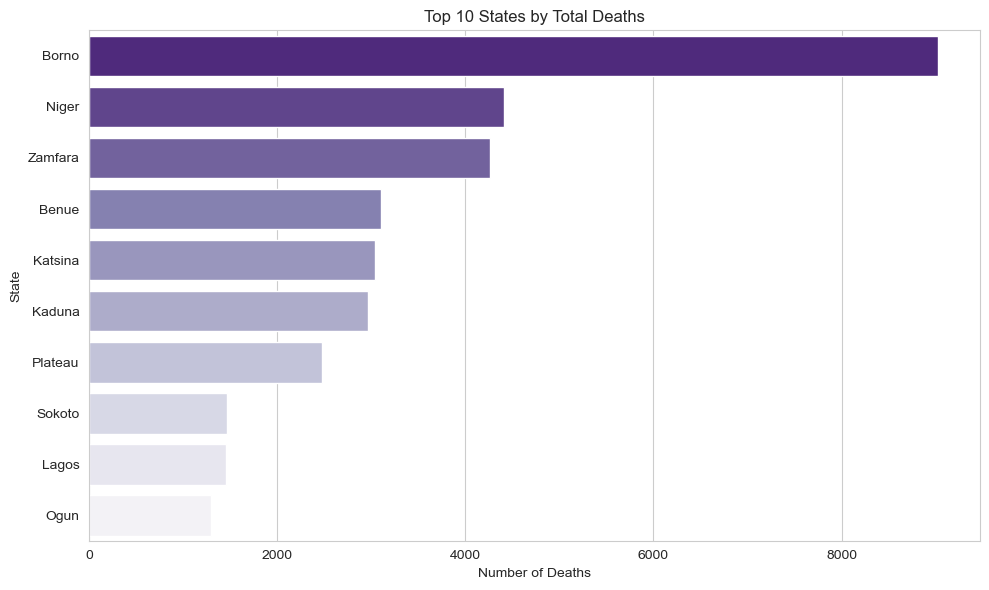

In [75]:

# Which states recorded the most deaths?

top10_states = df.groupby("State")["Number of deaths"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top10_states.values, y=top10_states.index, palette="Purples_r")
plt.title("Top 10 States by Total Deaths")
plt.xlabel("Number of Deaths")
plt.ylabel("State")
plt.tight_layout()
plt.show()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_8872\3218132965.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top10_causes.values, y=top10_causes.index, palette="Blues_r")


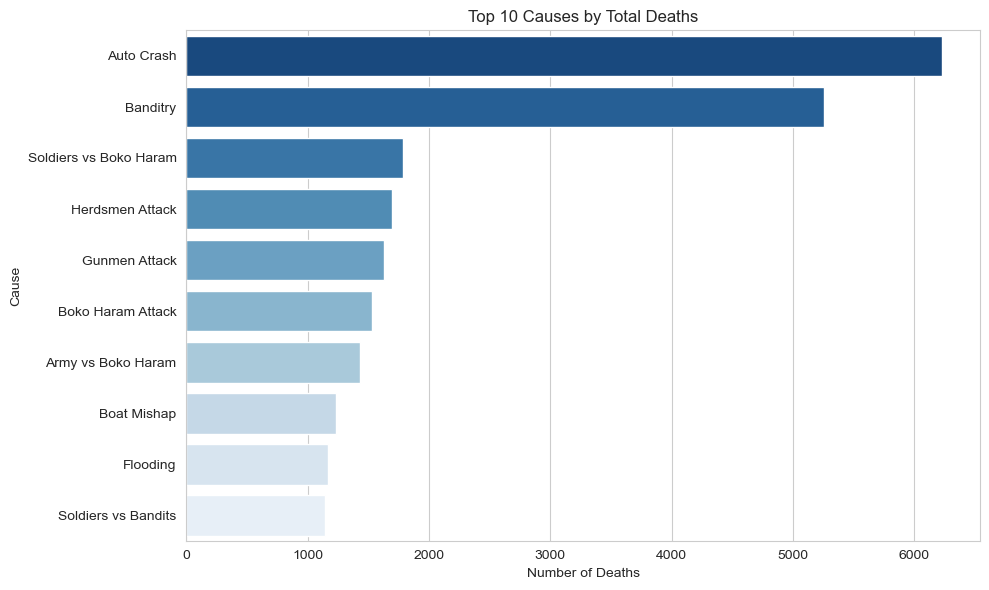

In [76]:
#What are the leading causes of death (from the Title/Cause column)?

df["Cause"] = df["Title"].str.rsplit(",", n=1).str[0]
top10_causes = df.groupby("Cause")["Number of deaths"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top10_causes.values, y=top10_causes.index, palette="Blues_r")
plt.title("Top 10 Causes by Total Deaths")
plt.xlabel("Number of Deaths")
plt.ylabel("Cause")
plt.tight_layout()
plt.show()

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

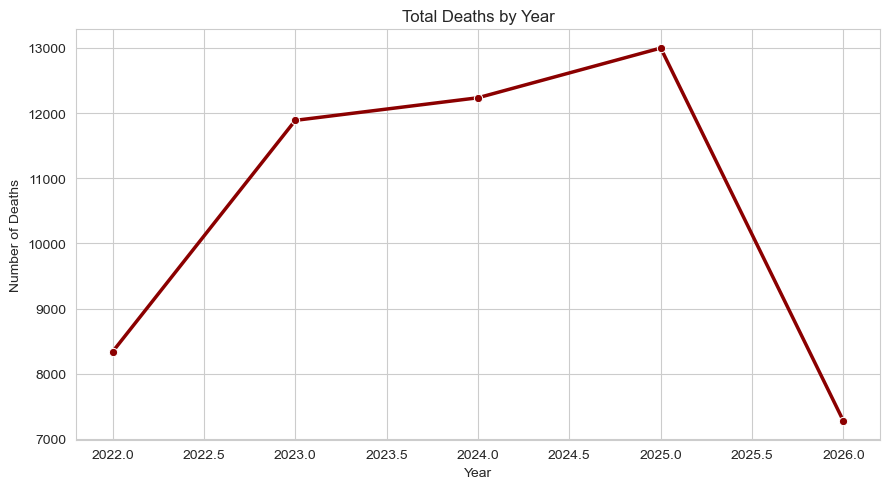

In [78]:
# Is the death toll rising or falling over time?
deaths_by_year = df.groupby("Year")["Number of deaths"].sum()

plt.figure(figsize=(9, 5))
sns.lineplot(x=deaths_by_year.index, y=deaths_by_year.values, marker="o", linewidth=2.5, color="darkred")
plt.title("Total Deaths by Year")
plt.xlabel("Year")
plt.ylabel("Number of Deaths")
plt.tight_layout()
plt.show()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_8872\610667313.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=deaths_by_month.index, y=deaths_by_month.values, palette="Reds_r")


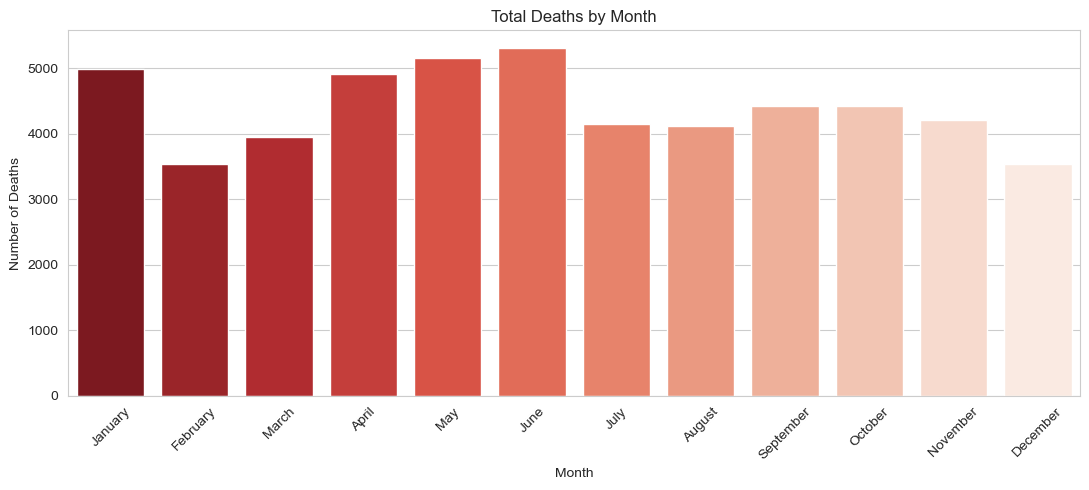

In [79]:
# Do deaths spike in certain months?

month_order = ["January","February","March","April","May","June",
               "July","August","September","October","November","December"]
deaths_by_month = df.groupby("Month Name")["Number of deaths"].sum().reindex(month_order)

plt.figure(figsize=(11, 5))
sns.barplot(x=deaths_by_month.index, y=deaths_by_month.values, palette="Reds_r")
plt.title("Total Deaths by Month")
plt.xlabel("Month")
plt.ylabel("Number of Deaths")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_8872\1537119836.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=deaths_by_dow.index, y=deaths_by_dow.values, palette="Greens_r")


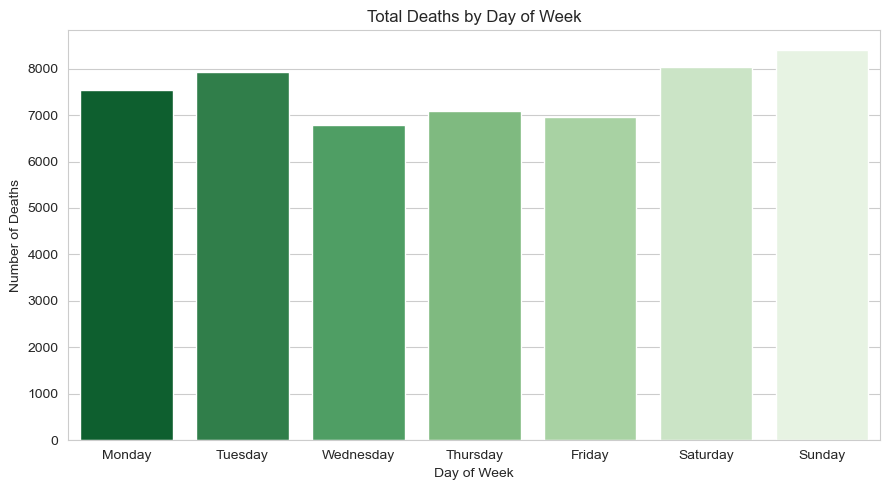

In [80]:
# day-of-week pattern

day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
deaths_by_dow = df.groupby("Day of Week")["Number of deaths"].sum().reindex(day_order)

plt.figure(figsize=(9, 5))
sns.barplot(x=deaths_by_dow.index, y=deaths_by_dow.values, palette="Greens_r")
plt.title("Total Deaths by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Deaths")
plt.tight_layout()
plt.show()

5 key findings from your analysis.

--Deaths are heavily concentrated in the North. Borno recorded the most deaths 
(9,111), more than double the next state, Niger (4,451) and Zamfara (4,321). 
The top 5 states (Borno, Niger, Zamfara, Benue, Katsina) 
account for 45.3% of all deaths nationwide, despite there being 37 states/FCT in the data.

--The death toll rose every year from 2022–2025, then 2026 looks lower only because the year isn't finished. Deaths climbed from 8,336 (2022) - 11,889 (2023) - 12,236 (2024) - 13,754 (2025), a 65% increase over three years. 2026 shows 7,272 so far, but that's only through September (data cutoff), not a real decline

-- Deaths peak in the middle of the year, not around holidays. June is the deadliest month (5,314 deaths, 19.2% above the monthly average), with the whole April–June stretch elevated likely tracking the rainy season (flooding, boat mishaps) rather than festive-period travel

-- Most incidents kill one person, but a handful of catastrophic events distort the total. 50.7% of all 10,978 incidents involved exactly one death. Yet the single deadliest incident ,flooding in Niger State on 2025-05-29 ,killed 440 people alone, meaning a tiny number of mass-casualty events (mostly flooding and boat mishaps) can swing state and monthly totals significantly.

In [81]:
import streamlit as st

In [82]:
st. title('hello world')

2026-10-07 11:04:09.271 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-10-07 11:04:10.883 
  command:

    streamlit run c:\Users\lenovo\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-07 11:04:10.885 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-07 11:04:10.886 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()